# makemore 第 3 部分：激活值、梯度、初始化与 BatchNorm

对应视频：Andrej Karpathy，*Building makemore Part 3: Activations & Gradients, BatchNorm*。
官方完整笔记本在 [github.com/karpathy/nn-zero-to-hero](https://github.com/karpathy/nn-zero-to-hero) 的 `lectures/makemore/makemore_part3_bn.ipynb`（MIT 许可）。这份是重新整理的版本，加了中文说明，并把视频里分散的实验整理成可以直接对比的函数。

**结构**

| 部分 | 内容 | 对应视频 |
|---|---|---|
| 第零部分 | 数据 | 与 Part 2 相同 |
| 第一部分 | 初始化的两个问题：初始损失过高、tanh 饱和；Kaiming 初始化 | 0:01:22–0:40:40 |
| 第二部分 | 手写 BatchNorm：原理、推理时的统计量、它带来的副作用 | 0:40:40–1:03:07 |
| 第三部分 | 把代码整理成自己的模块：`Linear`、`BatchNorm1d`、`Tanh` | 1:18:35–1:26:51 |
| 第四部分 | 诊断深层网络：激活值、梯度、参数梯度、更新量四种图 | 1:26:51–1:51:34 |
| 第五部分 | 完整训练、推理模式、采样 | — |
| 练习 | 每个只改一两行 | — |



## 第零部分：导入和数据

In [36]:
import math
import random

import torch
import torch.nn.functional as F   # 只用 F.cross_entropy 和 F.softmax。CS336 作业里这两个都不允许用，要自己写。
import matplotlib.pyplot as plt
%matplotlib inline

In [37]:
words = open("names.txt", "r").read().splitlines()

chars = sorted(set("".join(words)))
stoi = {ch: i + 1 for i, ch in enumerate(chars)}
stoi["."] = 0                     # "." 同时表示名字的开头和结尾
itos = {i: ch for ch, i in stoi.items()}
VOCAB = len(stoi)                 # 27
BLOCK = 3                         # 用前 3 个字符预测下一个字符


def build_dataset(ws):
    X, Y = [], []
    for w in ws:
        context = [0] * BLOCK
        for ch in w + ".":
            X.append(context)
            Y.append(stoi[ch])
            context = context[1:] + [stoi[ch]]
    return torch.tensor(X), torch.tensor(Y)


random.seed(42)
random.shuffle(words)
n1 = int(0.9 * len(words))
Xtr, Ytr = build_dataset(words[:n1])   # 训练集
Xva, Yva = build_dataset(words[n1:])   # 验证集
print("训练集", Xtr.shape, "验证集", tuple(Xva.shape))


训练集 torch.Size([205280, 3]) 验证集 (22866, 3)


In [38]:
# 通用工具：训练循环、计算损失、平滑损失曲线

def train_loop(params, logits_fn, steps, batch=32, seed=0, lr_fn=None):
    # logits_fn(X) 返回 logits。训练过程中需要做的额外事情（比如 BatchNorm 更新统计量）放在 logits_fn 里。
    if lr_fn is None:
        lr_fn = lambda i: 0.1 if i < steps//2 else 0.01   # 前一半大学习率，后一半调小
    g = torch.Generator().manual_seed(seed)
    lossi = []
    for i in range(steps):
        ix = torch.randint(0, Xtr.shape[0], (batch,), generator=g)
        loss = F.cross_entropy(logits_fn(Xtr[ix]), Ytr[ix])

        for p in params:
            p.grad = None              # 梯度是累加的，每步都要先清零
        loss.backward()

        lr = lr_fn(i)
        with torch.no_grad():          # 更新参数这一步本身不需要被求导
            for p in params:
                p -= lr * p.grad
        lossi.append(loss.log10().item())
    return lossi


@torch.no_grad()
def split_loss(logits_fn, X, Y):
    return F.cross_entropy(logits_fn(X), Y).item()


def smooth(lossi, k=1000):
    # 每 k 步取平均，让曲线不那么抖。要求总步数是 k 的整数倍。
    return torch.tensor(lossi).view(-1, k).mean(1)


## 第一部分：初始化的两个问题

**核心思想**：训练开始前，模型对 27 个字符应该"一无所知"，即每个字符的概率都约为 1/27，所以初始损失应该接近 $-\ln(1/27) \approx 3.30$。如果远高于这个值，说明初始化有问题。

这一部分比较三种初始化：

1. **不修正**：所有参数都直接用标准正态分布初始化；
2. **修正输出层**：把输出层缩小，让 logits 接近 0，模型一开始不会"自信地猜错"；
3. **两处都修正**：再按 Kaiming 初始化缩放隐藏层，避免 tanh 大面积饱和。

In [39]:
print(f"均匀猜测时的损失 -ln(1/27) = {-math.log(1 / VOCAB):.4f}")

均匀猜测时的损失 -ln(1/27) = 3.2958


In [40]:
N_EMBD = 10      # 每个字符的嵌入维度
N_HIDDEN = 200   # 隐藏层神经元个数


def init_mlp(fix_output, fix_hidden, seed=2147483647):
    g = torch.Generator().manual_seed(seed)
    C = torch.randn((VOCAB, N_EMBD), generator=g)
    W1 = torch.randn((BLOCK * N_EMBD, N_HIDDEN), generator=g)
    b1 = torch.randn(N_HIDDEN, generator=g)
    W2 = torch.randn((N_HIDDEN, VOCAB), generator=g)
    b2 = torch.randn(VOCAB, generator=g)

    if fix_output:
        # 问题 1：输出层初始值太大 → logits 很极端 → softmax 后某些字符的概率接近 1。
        # 模型一开始就"自信地猜错"，前几百步都在白白纠正这个错误。
        W2 = W2 * 0.01
        b2 = b2 * 0

    if fix_hidden:
        # 问题 2：隐藏层预激活值太大 → tanh 的输出大量挤在 ±1 附近（饱和）。
        # tanh 的导数是 1 - t²，t 接近 ±1 时导数接近 0，梯度传不回去，这些神经元学不动。
        # Kaiming 初始化：权重除以 sqrt(输入维度)，让输出方差和输入大致相同；
        # 再乘 tanh 的增益 5/3，补偿 tanh 对方差的压缩。
        W1 = W1 * (5 / 3) / math.sqrt(BLOCK * N_EMBD)
        b1 = b1 * 0.01

    params = [C, W1, b1, W2, b2]
    for p in params:
        p.requires_grad_(True)
    return params


def forward_mlp(params, X):
    C, W1, b1, W2, b2 = params
    emb = C[X]                                     # (B, 3, 10)
    hpre = emb.view(emb.shape[0], -1) @ W1 + b1    # (B, 200)  预激活值
    h = torch.tanh(hpre)                           # (B, 200)
    logits = h @ W2 + b2                           # (B, 27)
    return hpre, h, logits


CONFIGS = [  # (中文名, 图例用的英文名, 修正输出层, 修正隐藏层)
    ("不修正",     "no fix",           False, False),
    ("修正输出层", "fix output layer", True,  False),
    ("两处都修正", "fix both",         True,  True),
]

no fix: 初始损失 23.5060    tanh 饱和比例 61.8%    |logits| 平均 9.76


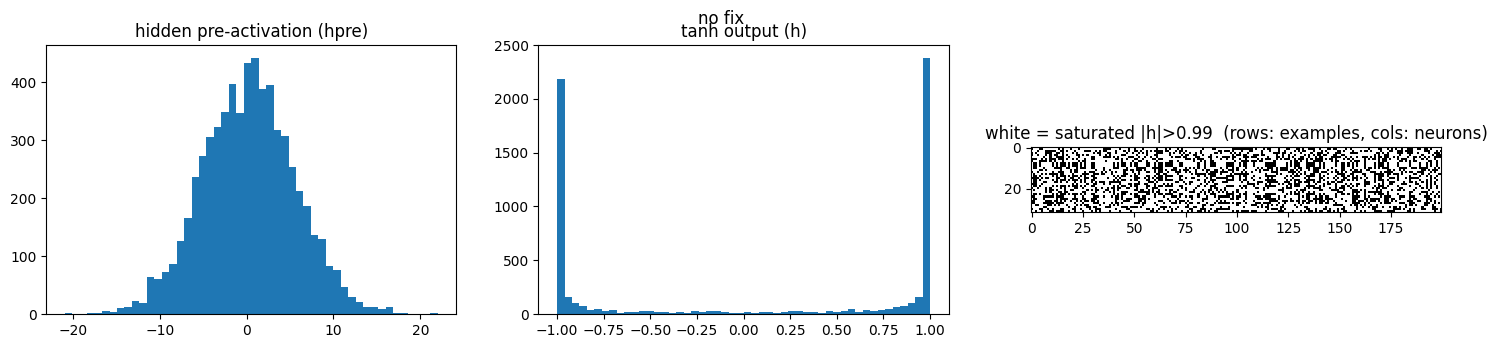

fix output layer: 初始损失 3.2808    tanh 饱和比例 61.8%    |logits| 平均 0.10


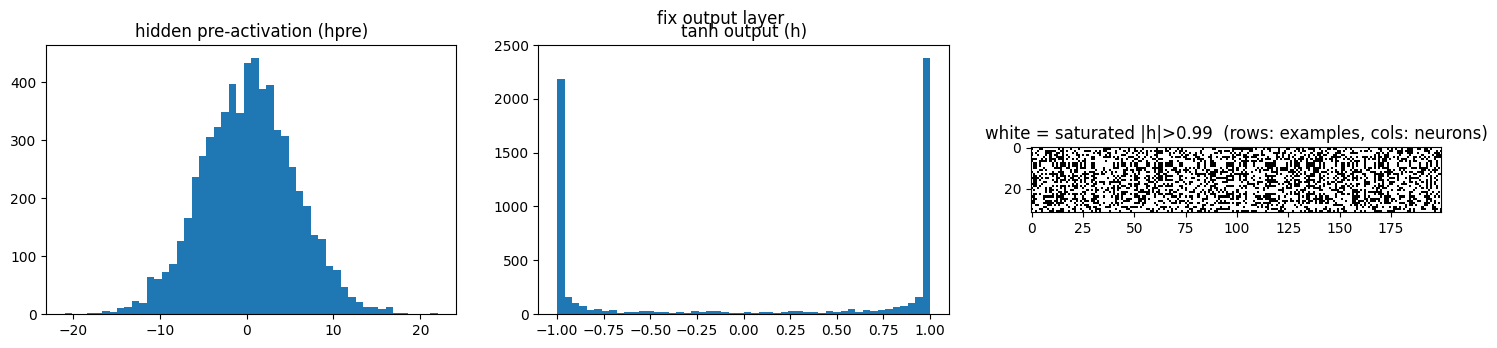

fix both: 初始损失 3.2834    tanh 饱和比例 9.3%    |logits| 平均 0.08


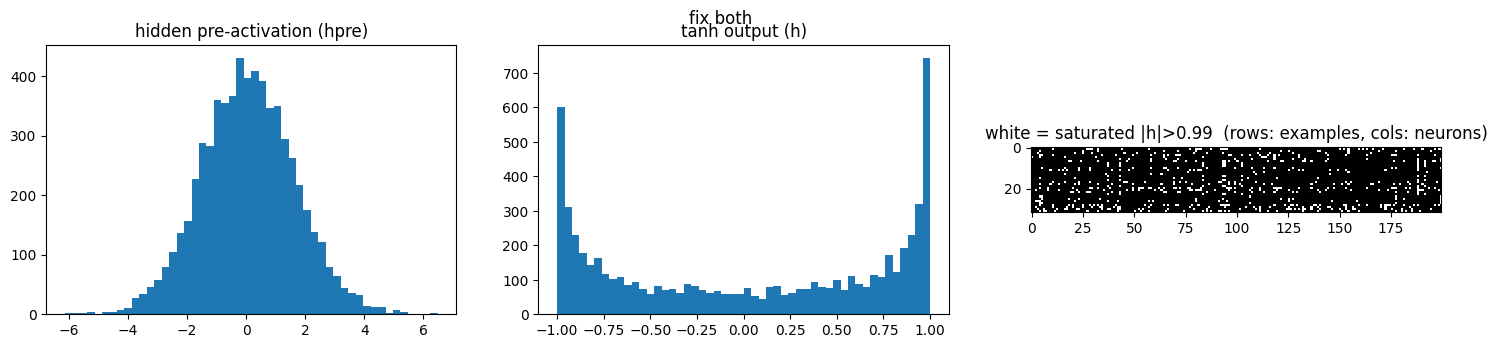

In [41]:
# 固定一个批次，用来观察初始化之后、训练之前的状态
ix_probe = torch.randint(0, Xtr.shape[0], (32,), generator=torch.Generator().manual_seed(1))


@torch.no_grad()
def show_init(params, title):
    hpre, h, logits = forward_mlp(params, Xtr[ix_probe])
    loss = F.cross_entropy(logits, Ytr[ix_probe]).item()
    sat = (h.abs() > 0.99).float().mean().item()
    print(f"{title}: 初始损失 {loss:.4f}    tanh 饱和比例 {sat:.1%}    |logits| 平均 {logits.abs().mean().item():.2f}")

    fig, axes = plt.subplots(1, 3, figsize=(18, 3.5))
    axes[0].hist(hpre.view(-1).tolist(), 50)
    axes[0].set_title("hidden pre-activation (hpre)")
    axes[1].hist(h.view(-1).tolist(), 50)
    axes[1].set_title("tanh output (h)")
    axes[2].imshow((h.abs() > 0.99).numpy(), cmap="gray", interpolation="nearest")
    axes[2].set_title("white = saturated |h|>0.99  (rows: examples, cols: neurons)")
    fig.suptitle(title)
    plt.show()


for name, en, fo, fh in CONFIGS:
    show_init(init_mlp(fo, fh), en)


**读图要点**

- **不修正**：初始损失远高于 3.30；`hpre` 的分布很宽，`h` 的直方图两端（±1）有很高的峰，右图大片白色。
- **修正输出层**：初始损失应该回到 3.30 附近，但 tanh 仍然大面积饱和。
- **两处都修正**：`hpre` 集中在 0 附近，`h` 的分布不再挤在两端，右图基本是黑的。

如果右图里有**一整列**都是白色，说明这个神经元对所有样本都饱和，它的梯度永远是 0，再也学不动了，这就是常说的"死神经元"。

不修正    训练集 2.2920    验证集 2.3043
修正输出层  训练集 2.1850    验证集 2.2109
两处都修正  训练集 2.1541    验证集 2.1723


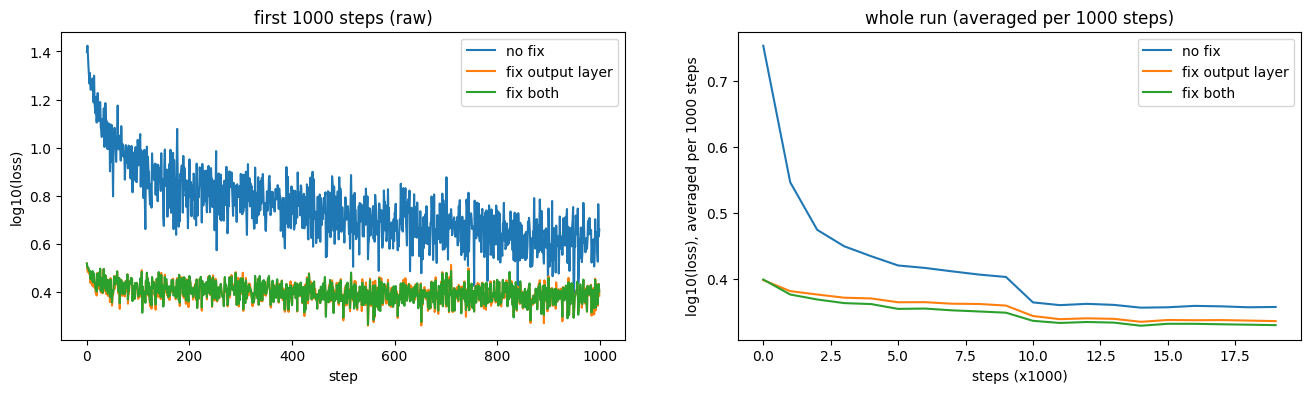

In [42]:
STEPS = 20000   # 视频用 200000 步。必须是 1000 的整数倍（画图时每 1000 步取平均）。

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for name, en, fo, fh in CONFIGS:
    params = init_mlp(fo, fh)
    f = lambda X, params=params: forward_mlp(params, X)[2]
    lossi = train_loop(params, f, STEPS)
    print(f"{name:<6} 训练集 {split_loss(f, Xtr, Ytr):.4f}    验证集 {split_loss(f, Xva, Yva):.4f}")
    axes[0].plot(lossi[:1000], label=en)    # 前 1000 步，不平滑
    axes[1].plot(smooth(lossi), label=en)   # 全程，每 1000 步取平均
axes[0].set_title("first 1000 steps (raw)")
axes[0].set_xlabel("step")
axes[0].set_ylabel("log10(loss)")
axes[1].set_title("whole run (averaged per 1000 steps)")
axes[1].set_xlabel("steps (x1000)")
axes[1].set_ylabel("log10(loss), averaged per 1000 steps")
for ax in axes:
    ax.legend()
plt.show()

**看什么**：三种初始化的验证集损失应该依次变好。

左图是前 1000 步、没有平滑的原始损失。"不修正"那条线从很高的地方开始（损失约 25，log10 约 1.4），在前几十步里急降到 9 左右，之后才慢下来。这段时间都在纠正"自信地猜错"，是白白浪费的。另外两条线一开始就在 3.3 附近（log10 约 0.52），没有这一段。

右图每 1000 步取一次平均，这段急降被压进了第一个点里，所以在右图上看不出来。

这个小网络只有一层隐藏层，所以即使初始化很差，最后也能训练得不错。网络越深，初始化问题越致命，第四部分会看到。

## 第二部分：BatchNorm

### 思路

第一部分的结论是：我们希望隐藏层的预激活值在初始化时均值约为 0、标准差约为 1，这样它们大多落在 ±2 以内，tanh 既不饱和、也不会几乎不起作用。真正要紧的是这两个数，而不是分布的形状。初始化时它的形状本来就接近正态分布：每个预激活值都是 30 个随机乘积 $x_i w_i$ 相加的结果，很多个独立的随机数相加，结果会接近正态分布（这叫中心极限定理）。所以视频里常把这个目标说成"单位高斯"（unit gaussian），但我们需要的其实只是均值和标准差对。手动调初始化能做到这一点，但网络一深、结构一复杂，就很难每层都算准。

BatchNorm 的想法很直接：**既然希望它均值为 0、方差为 1，那就在每一步训练里直接把它归一化成均值 0、方差 1**。具体做法是，对每个神经元，在当前这个批次上算均值和方差，减去均值、除以标准差。注意这只是把整个分布平移、缩放，不会改变分布的形状：原来偏向一侧的还是偏向一侧，原来有两个峰的还是两个峰。训练一段时间后，预激活值不一定再接近正态分布，BatchNorm 也不会把它变回正态分布。

用公式写，只看某一个神经元。设一个批次有 $m$ 个样本（这里 $m = 32$），这个神经元在它们上面的预激活值是 $x_1, x_2, \dots, x_m$：

$$\mu_B = \frac{1}{m}\sum_{i=1}^{m} x_i$$

$$\sigma_B^2 = \frac{1}{m}\sum_{i=1}^{m} (x_i - \mu_B)^2$$

$$\hat{x}_i = \frac{x_i - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}$$

- $\mu_B$、$\sigma_B^2$：这个批次上的均值和方差，下标 $B$ 表示"批次"（batch）。代码里是 `hpre.mean(0, keepdim=True)` 和 `hpre.var(0, keepdim=True)`：沿第 0 维（样本方向）计算，200 个神经元各算各的，得到形状 `(1, 200)`。
- $\epsilon$：一个很小的数（代码里是 `1e-5`），防止方差为 0 时除以 0。
- $\hat{x}_i$：归一化之后的值。在这个批次上，它的均值是 0，方差约等于 1。

代码里的 `var` 默认除以 $m-1$ 而不是 $m$（叫无偏估计），$m = 32$ 时两者只差约 3%，这里不用在意。

归一化里的每一步都是普通的加减乘除和开方，都可以求导，所以可以照常反向传播。

但如果永远强制均值 0、方差 1，网络就失去了调整分布位置和尺度的自由。所以归一化之后再乘一个可学习的增益 $\gamma$、加一个可学习的偏置 $\beta$：

$$y_i = \gamma\,\hat{x}_i + \beta$$

$\gamma$ 和 $\beta$ 在代码里是 `bngain` 和 `bnbias`，每个神经元各有一个。初始化成 1 和 0 时 $y_i = \hat{x}_i$，相当于一开始就是均值 0、方差 1，之后由训练决定要不要改。比如某个神经元的 $\gamma$ 学成 2、$\beta$ 学成 0.5，它的输出就变成均值 0.5、标准差 2 的分布。

### 三个细节

1. **推理时怎么办**？推理时可能一次只输入一个样本，没法算批次统计量。所以训练过程中顺手维护一份"全局"均值和方差的滑动平均，每一步这样更新：

   $$\mu_{\text{running}} \leftarrow (1 - \text{momentum})\cdot\mu_{\text{running}} + \text{momentum}\cdot\mu_B$$

   $$\sigma^2_{\text{running}} \leftarrow (1 - \text{momentum})\cdot\sigma^2_{\text{running}} + \text{momentum}\cdot\sigma_B^2$$

   `momentum` 是 0.001 时，每一步新值只占 0.1%、旧值占 99.9%，所以它大致相当于最近约 1000 步的平均。推理时用它们代替 $\mu_B$、$\sigma_B^2$：

   $$y = \gamma\,\frac{x - \mu_{\text{running}}}{\sqrt{\sigma^2_{\text{running}} + \epsilon}} + \beta$$

   这两个量不靠梯度更新，叫"缓冲区"，不叫参数。

2. **BatchNorm 前面那一层不需要偏置**。假设前一层给每个样本都加了同一个偏置 $b$，那么批次均值也正好多出 $b$，减均值时就消掉了：

   $$(x_i + b) - (\mu_B + b) = x_i - \mu_B$$

   方差也不受影响，因为整体平移不改变数据散开的程度。所以 $b$ 对输出没有任何作用，梯度也是 0，等于白加。它的作用由 BatchNorm 自己的 $\beta$ 接替。

3. **副作用：同一批次里的样本互相影响**。从公式看，$\hat{x}_i$ 里的 $\mu_B$ 和 $\sigma_B^2$ 是用整个批次算出来的，所以一个样本的输出取决于和它同批的其他样本，相当于给训练加了一点噪声。这有一定的正则化效果，但也让代码更容易出 bug，后面会用实验演示这一点。

In [43]:
def init_mlp_bn(seed=2147483647):
    g = torch.Generator().manual_seed(seed)
    C = torch.randn((VOCAB, N_EMBD), generator=g)
    W1 = torch.randn((BLOCK * N_EMBD, N_HIDDEN), generator=g) * (5 / 3) / math.sqrt(BLOCK * N_EMBD)
    # 没有 b1：后面的 BatchNorm 会减去均值，b1 加了等于白加
    W2 = torch.randn((N_HIDDEN, VOCAB), generator=g) * 0.01
    b2 = torch.zeros(VOCAB)
    bngain = torch.ones((1, N_HIDDEN))    # 可学习的增益，初始为 1
    bnbias = torch.zeros((1, N_HIDDEN))   # 可学习的偏置，初始为 0
    params = [C, W1, W2, b2, bngain, bnbias]
    for p in params:
        p.requires_grad_(True)
    # 缓冲区：不是参数，不靠梯度更新，而是在训练过程中用滑动平均统计出来，推理时使用
    buffers = {"mean": torch.zeros((1, N_HIDDEN)), "var": torch.ones((1, N_HIDDEN))}
    return params, buffers


def forward_bn(params, buffers, X, training, momentum=0.001, eps=1e-5):
    C, W1, W2, b2, bngain, bnbias = params
    emb = C[X]
    hpre = emb.view(emb.shape[0], -1) @ W1          # (B, 200)

    if training:
        mean = hpre.mean(0, keepdim=True)          # 每个神经元在这个批次上的均值，(1, 200)
        var = hpre.var(0, keepdim=True)            # 每个神经元在这个批次上的方差，(1, 200)
        with torch.no_grad():                      # 顺手更新全局统计量（滑动平均），不参与求导
            buffers["mean"] = (1 - momentum) * buffers["mean"] + momentum * mean
            buffers["var"] = (1 - momentum) * buffers["var"] + momentum * var
    else:
        mean, var = buffers["mean"], buffers["var"]

    hpre = bngain * (hpre - mean) / torch.sqrt(var + eps) + bnbias   # eps 防止除以 0
    h = torch.tanh(hpre)
    return h @ W2 + b2


BatchNorm 版本（推理模式）  训练集 2.1890    验证集 2.1989


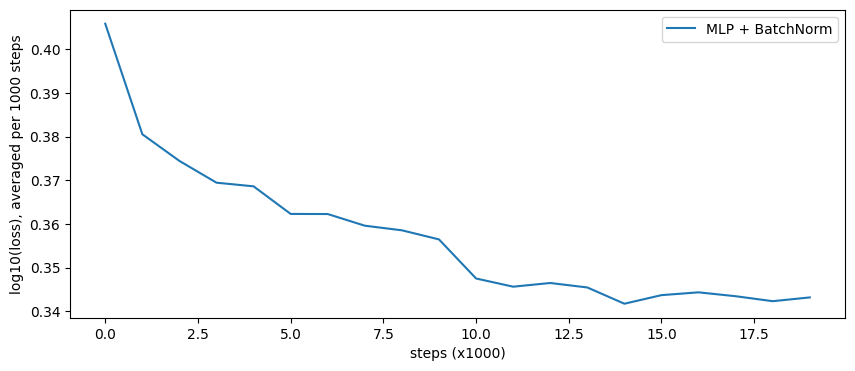

In [44]:
params_bn, buffers_bn = init_mlp_bn()
f_train = lambda X: forward_bn(params_bn, buffers_bn, X, training=True)
f_eval = lambda X: forward_bn(params_bn, buffers_bn, X, training=False)

lossi_bn = train_loop(params_bn, f_train, STEPS)
print(f"BatchNorm 版本（推理模式）  训练集 {split_loss(f_eval, Xtr, Ytr):.4f}    验证集 {split_loss(f_eval, Xva, Yva):.4f}")



plt.figure(figsize=(10, 4))
plt.plot(smooth(lossi_bn), label="MLP + BatchNorm")
plt.xlabel("steps (x1000)")
plt.ylabel("log10(loss), averaged per 1000 steps")
plt.legend()
plt.show()

### 实验：滑动平均估计得准不准？

另一种做法是训练结束后，把整个训练集过一遍，直接算出准确的均值和方差（叫"校准"）。下面比较两者的差距，以及分别用它们推理时的损失。

In [45]:
with torch.no_grad():
    C_, W1_ = params_bn[0], params_bn[1]
    hpre_all = C_[Xtr].view(Xtr.shape[0], -1) @ W1_
    calibrated = {"mean": hpre_all.mean(0, keepdim=True), "var": hpre_all.var(0, keepdim=True)}

print("滑动平均 vs 校准：均值的最大差异", (buffers_bn["mean"] - calibrated["mean"]).abs().max().item())
print("滑动平均 vs 校准：方差的最大相对差异", ((buffers_bn["var"] - calibrated["var"]).abs() / calibrated["var"]).max().item())

f_cal = lambda X: forward_bn(params_bn, calibrated, X, training=False)
print(f"用滑动平均推理  验证集 {split_loss(f_eval, Xva, Yva):.4f}")
print(f"用校准值推理    验证集 {split_loss(f_cal, Xva, Yva):.4f}")

滑动平均 vs 校准：均值的最大差异 0.023006021976470947
滑动平均 vs 校准：方差的最大相对差异 0.0172961987555027
用滑动平均推理  验证集 2.1989
用校准值推理    验证集 2.1988


### 实验：同一批次里的样本互相影响

把同一个样本放进两个不同的批次。训练模式下，它的输出会不一样；推理模式下，输出完全相同。

In [46]:
with torch.no_grad():
    x0 = Xtr[:1]                                   # 同一个样本
    batch_a = torch.cat([x0, Xtr[100:131]])        # 和 31 个样本组成批次 A
    batch_b = torch.cat([x0, Xtr[5000:5031]])      # 和另外 31 个样本组成批次 B
    # momentum=0.0：这次前向不改动缓冲区
    out_a = forward_bn(params_bn, buffers_bn, batch_a, training=True, momentum=0.0)[0]
    out_b = forward_bn(params_bn, buffers_bn, batch_b, training=True, momentum=0.0)[0]
    print("训练模式：同一个样本在两个批次里的 logits 最大差异", (out_a - out_b).abs().max().item())

    out_a = forward_bn(params_bn, buffers_bn, batch_a, training=False)[0]
    out_b = forward_bn(params_bn, buffers_bn, batch_b, training=False)[0]
    print("推理模式：同一个样本在两个批次里的 logits 最大差异", (out_a - out_b).abs().max().item())

训练模式：同一个样本在两个批次里的 logits 最大差异 0.6920090317726135
推理模式：同一个样本在两个批次里的 logits 最大差异 0.0


### 和 CS336 第一次作业的关系

Transformer 一般不用 BatchNorm，而用 LayerNorm 或 RMSNorm（作业要你实现的就是 RMSNorm）。区别在于**沿哪个方向归一化**：

| | BatchNorm | LayerNorm / RMSNorm |
|---|---|---|
| 归一化的方向 | 同一个特征，跨批次里的样本 | 同一个样本，跨它的所有特征 |
| 样本之间是否互相影响 | 是 | 否 |
| 训练和推理行为是否一致 | 否，需要滑动平均的缓冲区 | 是，不需要缓冲区 |
| 是否减去均值 | 是 | LayerNorm 是；RMSNorm 否，只除以均方根 |

正因为后者不依赖批次、训练和推理一致，它更适合处理变长序列、一次只生成一个记号的 Transformer。作业里还有一个去掉 RMSNorm 再训练的消融实验，到时可以回想这一部分讲的：归一化的作用就是让每层的激活值保持在合适的范围里。

## 第三部分：把代码整理成自己的模块

下面手写的 `Linear`、`BatchNorm1d`、`Tanh`，接口形状和 PyTorch 的 `nn.Module` 一样：调用时做前向计算，`parameters()` 返回需要训练的参数，`BatchNorm1d` 还有一个 `training` 开关。

和 CS336 作业的区别：这里没有继承 `nn.Module`，参数也不是 `nn.Parameter`，作业里要用这两者。另外每个模块都把输出存在 `self.out` 里，只是为了方便第四部分做诊断。

In [47]:
class Linear:
    def __init__(self, fan_in, fan_out, bias=True, g=None):
        # 除以 sqrt(fan_in)：在不考虑激活函数时，让输出的方差和输入大致相同
        self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in ** 0.5
        self.bias = torch.zeros(fan_out) if bias else None

    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out = self.out + self.bias
        return self.out

    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])



class BatchNorm1d:
    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps 
        self.momentum = momentum 
        self.training = True 
        # 参数：靠梯度更新
        self.gamma = torch.ones(dim) 
        self.beta = torch.zeros(dim) 
        # 缓冲区：靠滑动平均更新
        self.running_mean = torch.zeros(dim) 
        self.running_var = torch.ones(dim)

    def __call__(self, x):
        if self.training:
            xmean = x.mean(0, keepdim=True) 
            xvar = x.var(0, keepdim=True)
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean 
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
        else: 
            xmean = self.running_mean 
            xvar = self.running_var 
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps)
        self.out = self.gamma * xhat + self.beta
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]



class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x) 
        return self.out 

    def parameters(self):
        return []

In [48]:
def build_deep(gain=5 / 3, use_bn=False, use_tanh=True, n_layers=5, n_hidden=100, seed=2147483647):
    # 结构：[Linear → (BatchNorm) → (Tanh)] × n_layers → Linear → (BatchNorm)
    g = torch.Generator().manual_seed(seed)
    C = torch.randn((VOCAB, N_EMBD), generator=g)

    sizes = [BLOCK * N_EMBD] + [n_hidden] * n_layers
    layers = []
    for fan_in, fan_out in zip(sizes[:-1], sizes[1:]):
        layers.append(Linear(fan_in, fan_out, bias=not use_bn, g=g))   # 后面接 BatchNorm 时不要偏置
        if use_bn:
            layers.append(BatchNorm1d(fan_out))
        if use_tanh:
            layers.append(Tanh())
    layers.append(Linear(n_hidden, VOCAB, bias=not use_bn, g=g))
    if use_bn:
        layers.append(BatchNorm1d(VOCAB))

    linears = [layer for layer in layers if isinstance(layer, Linear)]
    with torch.no_grad():
        for layer in linears[:-1]:
            layer.weight *= gain          # tanh 会压缩方差，用增益补回来
        # 让输出层一开始不要太自信（和第一部分同理）
        if use_bn:
            layers[-1].gamma *= 0.1
        else:
            linears[-1].weight *= 0.1

    params = [C] + [p for layer in layers for p in layer.parameters()]
    for p in params:
        p.requires_grad_(True)
    print(f"参数总数 {sum(p.nelement() for p in params)}")
    return C, layers, params


def forward_deep(C, layers, X):
    x = C[X].view(X.shape[0], -1)
    for layer in layers:
        x = layer(x)
    return x   # logits


def set_training(layers, mode):
    for layer in layers:
        if hasattr(layer, "training"):
            layer.training = mode

## 第四部分：诊断深层网络

一个 5 层的网络训练 1000 步，然后看四种图：

1. **前向激活值的分布**：各层 tanh 输出的均值、标准差、饱和比例（|输出| > 0.97 的比例）。健康的样子是各层的标准差大致稳定，不会一层层变大或缩到 0。饱和比例方面，**第 1 层偏高一些是正常的**（正确初始化下约 20%）：第 1 层的输入是嵌入 `C`，`C` 本身就服从标准正态分布，乘上增益 5/3 后，预激活值的分布偏宽。后面各层在初始化时约 5–10%，训练 1000 步后会升到 10–15% 左右。要警惕的是大多数层都到 40% 以上（实验 3）。
2. **反向梯度的分布**：各层 tanh 输出的梯度。健康的样子是各层大致相同；越往前越小叫梯度消失，越往前越大叫梯度爆炸。
3. **参数梯度的分布**：每个权重矩阵的"梯度标准差 ÷ 参数标准差"。如果某一层明显比其他层大很多，这一层会被更新得过猛。**但最后一层（输出层，形状 `(100, 27)`）的比值比其他层大约 10 倍，这是正常的**：它初始化时故意乘了 0.1（让模型一开始不要太自信），参数的标准差很小，比值的分母就小。
4. **更新量与参数之比随时间的变化**：每一步"学习率 × 梯度"的标准差除以参数的标准差，取 log10。经验上 −3 左右（更新量约为参数的千分之一）比较健康：明显高于 −3，学习率可能太大；明显低于 −3，这一层几乎没在学。同样的原因，输出层这条线会明显高于其他层（约 −1 到 −1.5），并随着训练慢慢回落。

前三张图画的是训练 1000 步之后、最后那一步的状态；第四张图画的是这 1000 步里的变化过程。

训练本身会修正一部分初始化的问题，所以训练 1000 步之后再看，初始化的好坏就没那么明显了。为此第一张图除了画训练后的分布，还会额外打印**初始化时**（第 0 步，还没更新过参数）各层的标准差和饱和比例，也就是输出里 `init` 那一列。预测初始化的效果时，主要看这一列。

In [49]:
def train_with_tracking(C, layers, params, steps, lr=0.1, batch=32, seed=0):
    set_training(layers, True)
    g = torch.Generator().manual_seed(seed)
    lossi, ud, init = [], [], {}
    for i in range(steps):
        ix = torch.randint(0, Xtr.shape[0], (batch,), generator=g)
        loss = F.cross_entropy(forward_deep(C, layers, Xtr[ix]), Ytr[ix])
        if i == 0:
            # 第 0 步的前向发生在任何参数更新之前，这时各层的输出就是初始化时的状态
            for j, layer in enumerate(layers):
                t = layer.out.detach()
                init[j] = (t.std().item(), (t.abs() > 0.97).float().mean().item())

        for layer in layers:
            layer.out.retain_grad()   # 中间结果默认不保存梯度，这里为了诊断才保留
        for p in params:
            p.grad = None
        loss.backward()

        with torch.no_grad():
            for p in params:
                p -= lr * p.grad
            ud.append([((lr * p.grad).std() / p.data.std()).log10().item() for p in params])
        lossi.append(loss.log10().item())
    return lossi, ud, init


def _watched(layers):
    # 有 Tanh 就看 Tanh 的输出；没有（纯线性网络）就看除最后一层外的 Linear
    kind = Tanh if any(isinstance(l, Tanh) for l in layers) else Linear
    return [(i, l) for i, l in enumerate(layers[:-1]) if isinstance(l, kind)], kind.__name__


def plot_activations(layers, title, init):
    plt.figure(figsize=(20, 4))
    watched, kind = _watched(layers)
    for i, layer in watched:
        t = layer.out.detach()
        sat = (t.abs() > 0.97).float().mean().item()
        std0, sat0 = init[i]
        print(f"layer {i:2d} ({kind}): init std {std0:.2f}, saturated {sat0:6.2%}  |  "
              f"after training: mean {t.mean().item():+.2f}, std {t.std().item():.2f}, saturated {sat:6.2%}")
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1], hy, label=f"layer {i}")
    plt.legend()
    plt.title(f"activation distribution  [{title}]")
    plt.show()


def plot_gradients(layers, title):
    plt.figure(figsize=(20, 4))
    watched, kind = _watched(layers)
    for i, layer in watched:
        t = layer.out.grad
        print(f"layer {i:2d} ({kind}): grad mean {t.mean().item():+.2e}, grad std {t.std().item():.2e}")
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1], hy, label=f"layer {i}")
    plt.legend()
    plt.title(f"gradient distribution  [{title}]")
    plt.show()


def plot_weight_grads(params, title):
    plt.figure(figsize=(20, 4))
    for i, p in enumerate(params):
        if p.ndim == 2:
            t = p.grad
            print(f"weight {str(tuple(p.shape)):<10} | grad std {t.std().item():.2e} | grad:data ratio {(t.std() / p.data.std()).item():.2e}")
            hy, hx = torch.histogram(t, density=True)
            plt.plot(hx[:-1], hy, label=f"{i} {tuple(p.shape)}")
    plt.legend()
    plt.title(f"weight gradient distribution  [{title}]")
    plt.show()


def plot_update_ratio(ud, params, title):
    plt.figure(figsize=(20, 4))
    for i, p in enumerate(params):
        if p.ndim == 2:
            plt.plot([ud[j][i] for j in range(len(ud))], label=f"param {i} {tuple(p.shape)}")
    plt.plot([0, len(ud)], [-3, -3], "k", label="-3 (reference)")
    plt.legend()
    plt.title(f"log10(update / data) over steps  [{title}]")
    plt.show()


def diagnose(title, steps=1000, lr=0.1, **build_kwargs):
    C, layers, params = build_deep(**build_kwargs)
    lossi, ud, init = train_with_tracking(C, layers, params, steps, lr=lr)
    print(f"[{title}] 最后 100 步的平均损失 {10 ** torch.tensor(lossi[-100:]).mean().item():.4f}")
    plot_activations(layers, title, init)
    plot_gradients(layers, title)
    plot_weight_grads(params, title)
    plot_update_ratio(ud, params, title)

### 实验 1：没有 BatchNorm，增益 5/3（正确的 Kaiming 初始化）

这是基准：各层的标准差大致稳定；除第 1 层外，饱和比例不高；各层梯度大小接近；输出层的"梯度 ÷ 参数"比值比其他层大约 10 倍（原因见上面第 3 条）。

参数总数 46497
[no BN, gain 5/3] 最后 100 步的平均损失 2.3541
layer  1 (Tanh): init std 0.75, saturated 19.31%  |  after training: mean -0.05, std 0.77, saturated 21.41%
layer  3 (Tanh): init std 0.68, saturated  8.03%  |  after training: mean -0.01, std 0.73, saturated 13.03%
layer  5 (Tanh): init std 0.67, saturated  7.66%  |  after training: mean +0.02, std 0.74, saturated 15.00%
layer  7 (Tanh): init std 0.66, saturated  5.91%  |  after training: mean -0.02, std 0.73, saturated 12.78%
layer  9 (Tanh): init std 0.66, saturated  6.50%  |  after training: mean -0.02, std 0.71, saturated  9.94%


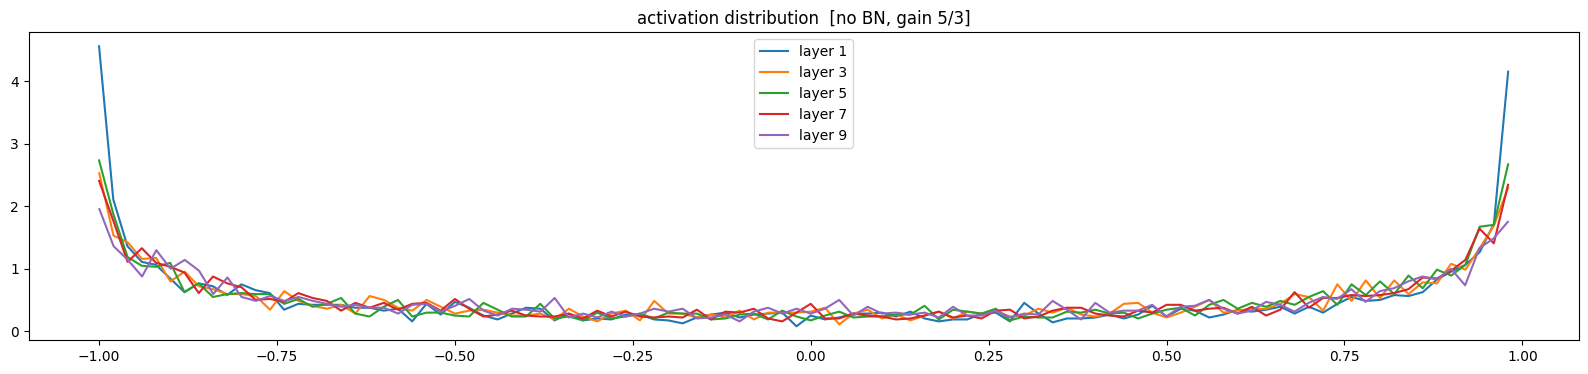

layer  1 (Tanh): grad mean +4.85e-05, grad std 2.70e-03
layer  3 (Tanh): grad mean -1.68e-05, grad std 2.61e-03
layer  5 (Tanh): grad mean -4.18e-06, grad std 2.62e-03
layer  7 (Tanh): grad mean +3.23e-05, grad std 2.55e-03
layer  9 (Tanh): grad mean -2.25e-05, grad std 2.22e-03


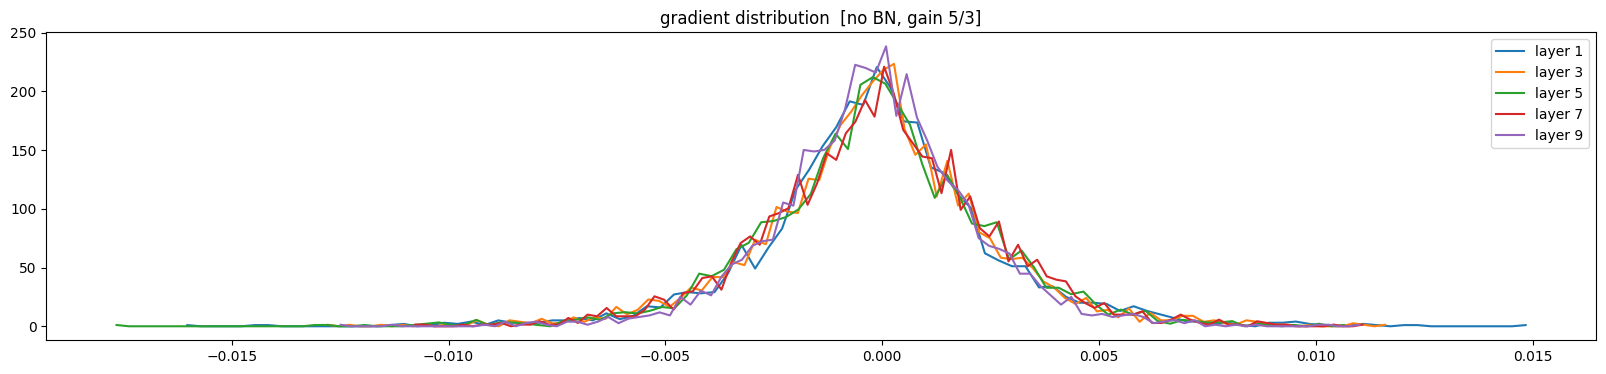

weight (27, 10)   | grad std 8.23e-03 | grad:data ratio 8.22e-03
weight (30, 100)  | grad std 8.30e-03 | grad:data ratio 2.65e-02
weight (100, 100) | grad std 6.29e-03 | grad:data ratio 3.74e-02
weight (100, 100) | grad std 5.66e-03 | grad:data ratio 3.33e-02
weight (100, 100) | grad std 5.62e-03 | grad:data ratio 3.33e-02
weight (100, 100) | grad std 5.05e-03 | grad:data ratio 3.00e-02
weight (100, 27)  | grad std 2.15e-02 | grad:data ratio 3.08e-01


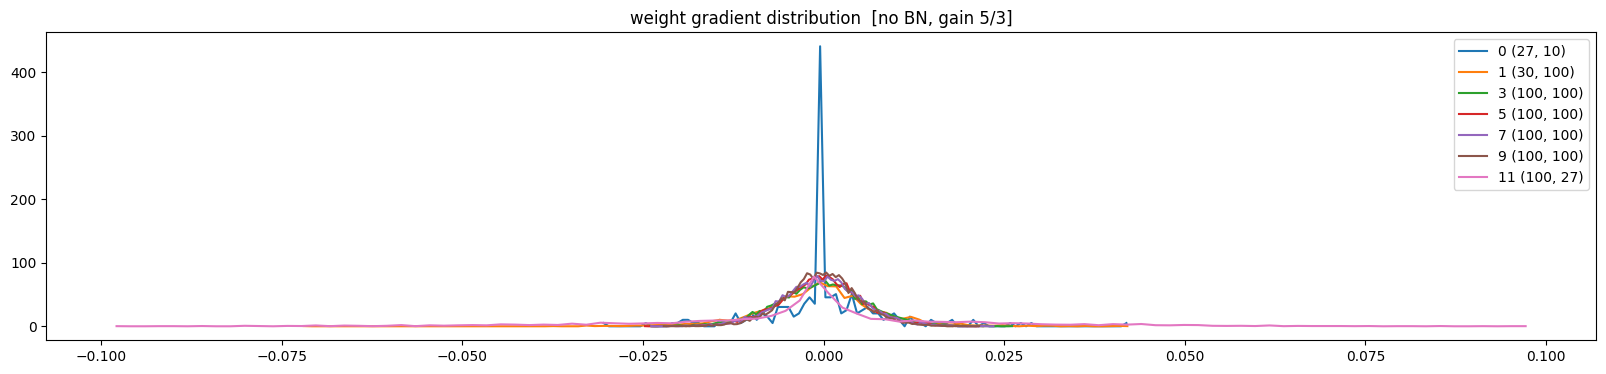

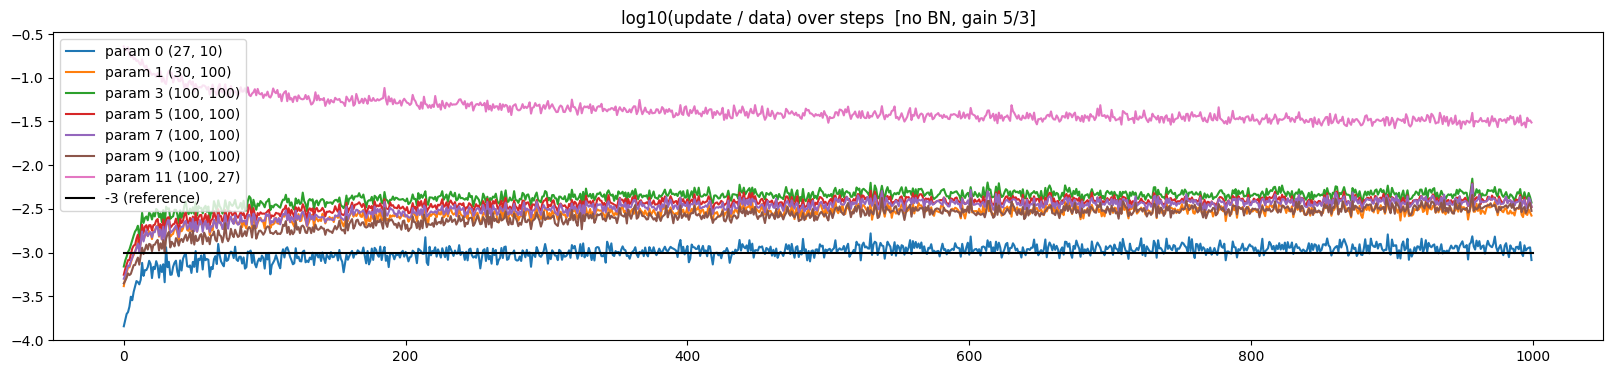

In [50]:
diagnose("no BN, gain 5/3", gain=5 / 3)

### 实验 2：没有 BatchNorm，增益 1.0（太小）

先预测再运行：每经过一层 tanh，方差都会被压缩一点，又没有增益补回来，所以越往后的层，激活值的标准差应该越小。

看 `init` 那一列会很明显。训练 1000 步之后，网络已经自己把权重调大了一些，衰减就不那么明显了。这个 5 层的网络还能靠训练补救，但不要指望总能这样：网络越深，逐层的衰减累积得越厉害，训练也越难把它拉回来。

参数总数 46497
[no BN, gain 1.0] 最后 100 步的平均损失 2.4100
layer  1 (Tanh): init std 0.62, saturated  3.59%  |  after training: mean -0.04, std 0.64, saturated  5.62%
layer  3 (Tanh): init std 0.47, saturated  0.03%  |  after training: mean -0.00, std 0.56, saturated  0.41%
layer  5 (Tanh): init std 0.41, saturated  0.03%  |  after training: mean +0.01, std 0.54, saturated  0.53%
layer  7 (Tanh): init std 0.35, saturated  0.00%  |  after training: mean -0.02, std 0.53, saturated  0.19%
layer  9 (Tanh): init std 0.32, saturated  0.00%  |  after training: mean -0.01, std 0.54, saturated  0.12%


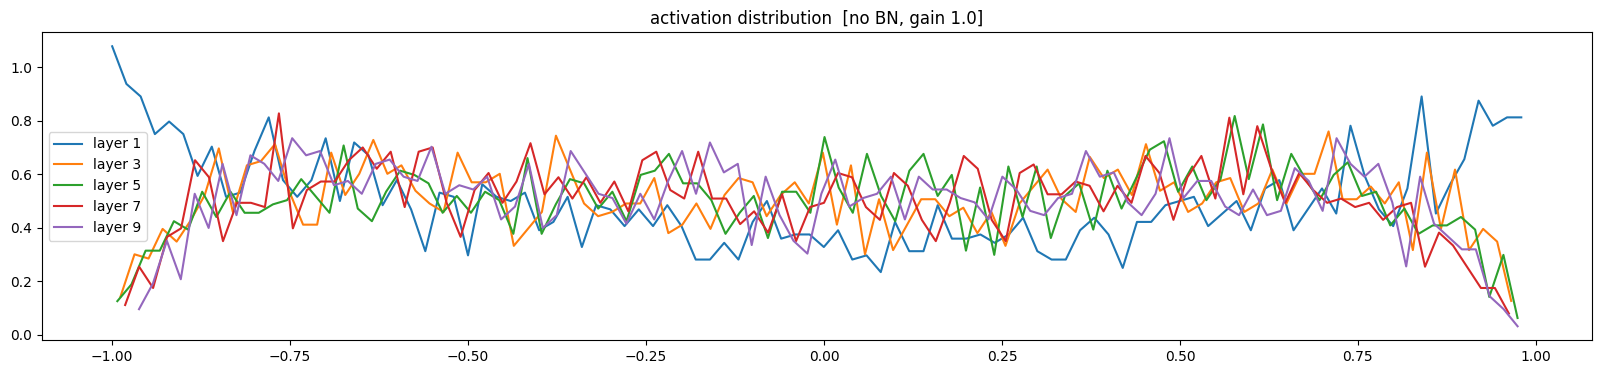

layer  1 (Tanh): grad mean +1.16e-05, grad std 2.20e-03
layer  3 (Tanh): grad mean +1.11e-06, grad std 2.22e-03
layer  5 (Tanh): grad mean +3.05e-05, grad std 2.28e-03
layer  7 (Tanh): grad mean +7.16e-05, grad std 2.19e-03
layer  9 (Tanh): grad mean -1.67e-06, grad std 1.99e-03


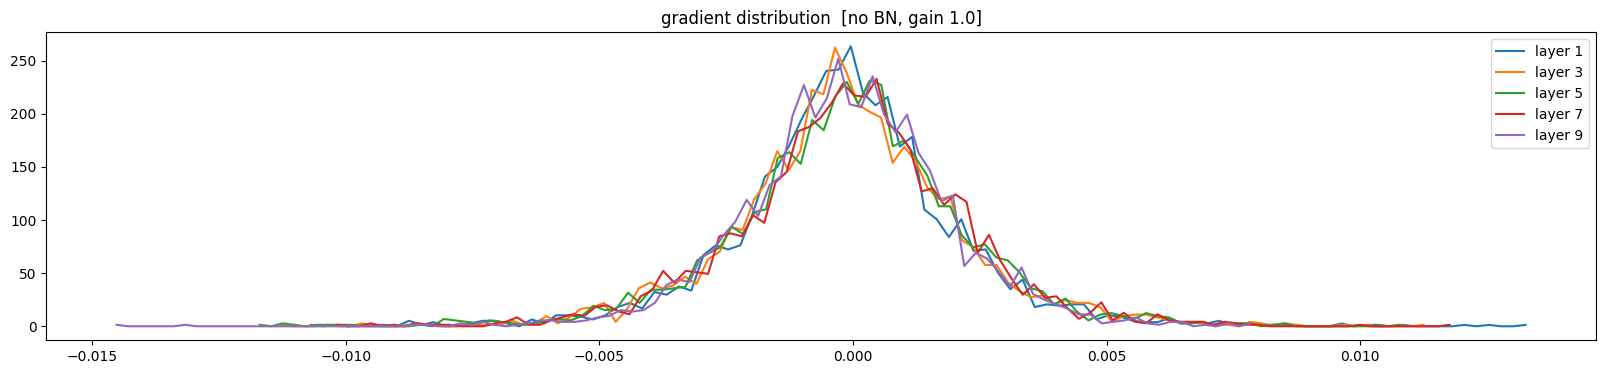

weight (27, 10)   | grad std 6.59e-03 | grad:data ratio 6.55e-03
weight (30, 100)  | grad std 8.08e-03 | grad:data ratio 4.22e-02
weight (100, 100) | grad std 5.46e-03 | grad:data ratio 5.28e-02
weight (100, 100) | grad std 4.96e-03 | grad:data ratio 4.79e-02
weight (100, 100) | grad std 4.81e-03 | grad:data ratio 4.68e-02
weight (100, 100) | grad std 4.11e-03 | grad:data ratio 4.01e-02
weight (100, 27)  | grad std 1.60e-02 | grad:data ratio 2.52e-01


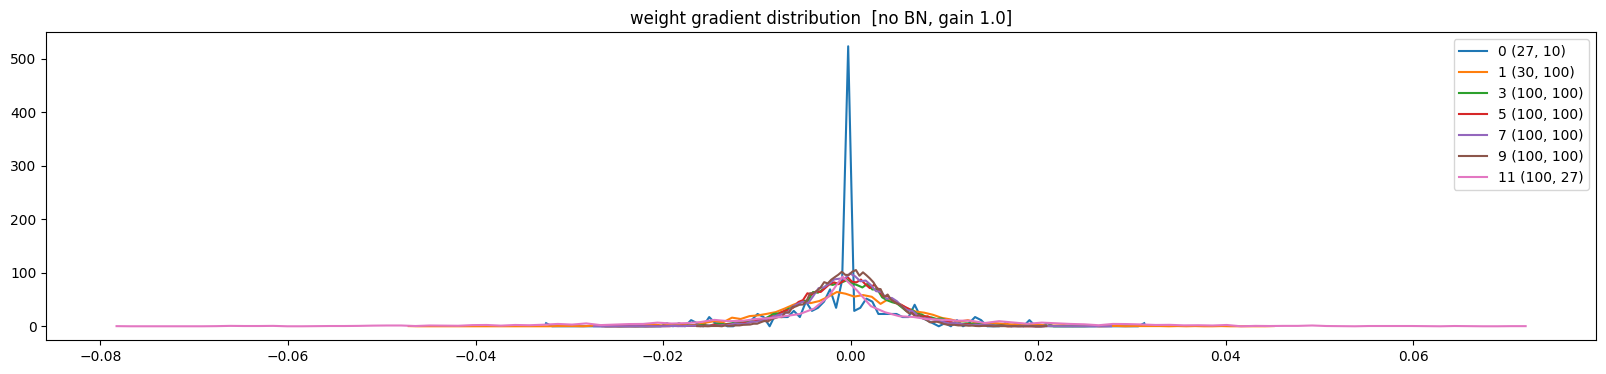

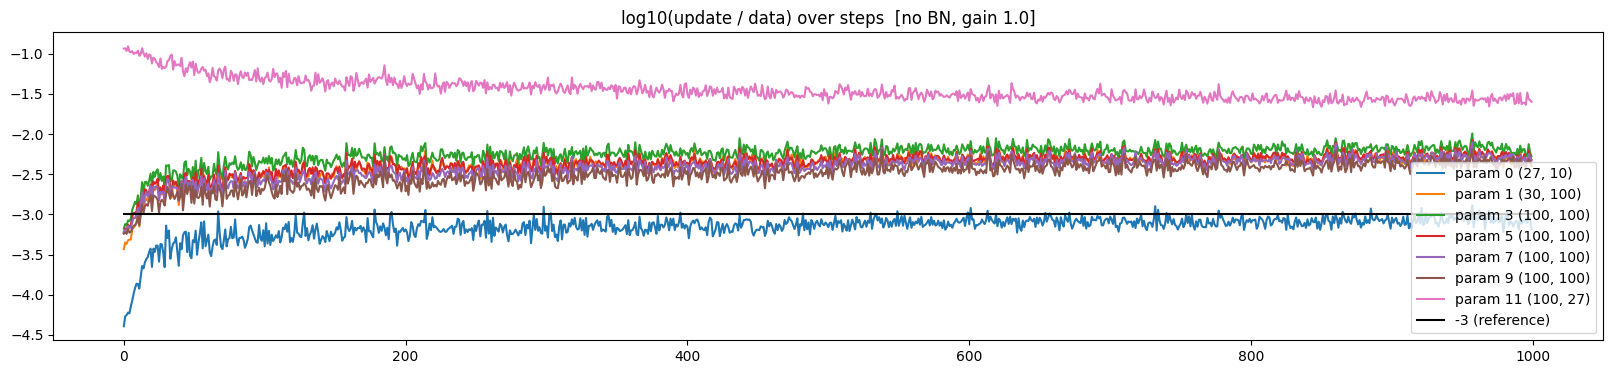

In [51]:
diagnose("no BN, gain 1.0", gain=1.0)

### 实验 3：没有 BatchNorm，增益 3.0（太大）

预测：各层的饱和比例明显上升。

参数总数 46497
[no BN, gain 3.0] 最后 100 步的平均损失 2.3897
layer  1 (Tanh): init std 0.86, saturated 47.16%  |  after training: mean -0.05, std 0.87, saturated 50.13%
layer  3 (Tanh): init std 0.84, saturated 40.59%  |  after training: mean -0.01, std 0.86, saturated 44.19%
layer  5 (Tanh): init std 0.85, saturated 42.91%  |  after training: mean +0.01, std 0.87, saturated 45.53%
layer  7 (Tanh): init std 0.84, saturated 40.53%  |  after training: mean -0.04, std 0.86, saturated 43.34%
layer  9 (Tanh): init std 0.84, saturated 42.63%  |  after training: mean -0.02, std 0.86, saturated 45.72%


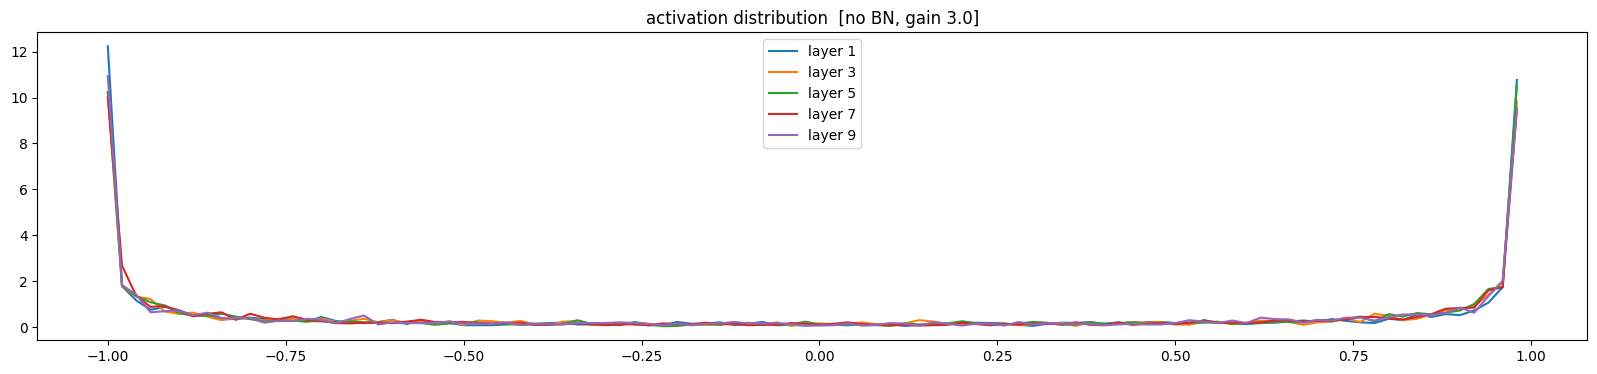

layer  1 (Tanh): grad mean -3.36e-05, grad std 5.92e-03
layer  3 (Tanh): grad mean +3.72e-05, grad std 4.52e-03
layer  5 (Tanh): grad mean +2.96e-05, grad std 3.79e-03
layer  7 (Tanh): grad mean -3.24e-05, grad std 3.08e-03
layer  9 (Tanh): grad mean +5.86e-05, grad std 2.34e-03


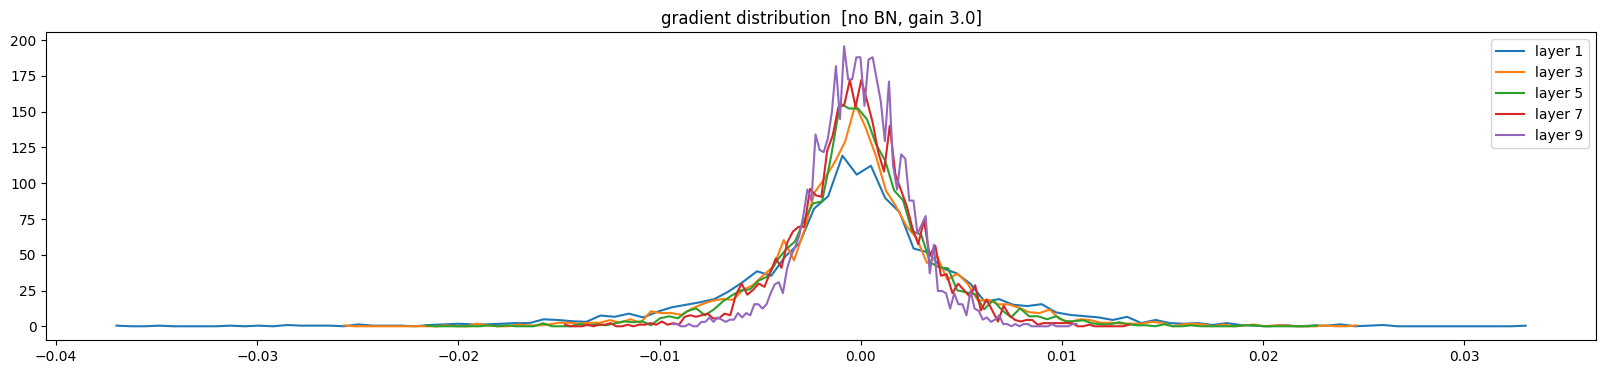

weight (27, 10)   | grad std 2.19e-02 | grad:data ratio 2.19e-02
weight (30, 100)  | grad std 1.40e-02 | grad:data ratio 2.49e-02
weight (100, 100) | grad std 1.04e-02 | grad:data ratio 3.47e-02
weight (100, 100) | grad std 7.14e-03 | grad:data ratio 2.36e-02
weight (100, 100) | grad std 6.18e-03 | grad:data ratio 2.05e-02
weight (100, 100) | grad std 4.66e-03 | grad:data ratio 1.55e-02
weight (100, 27)  | grad std 2.60e-02 | grad:data ratio 3.56e-01


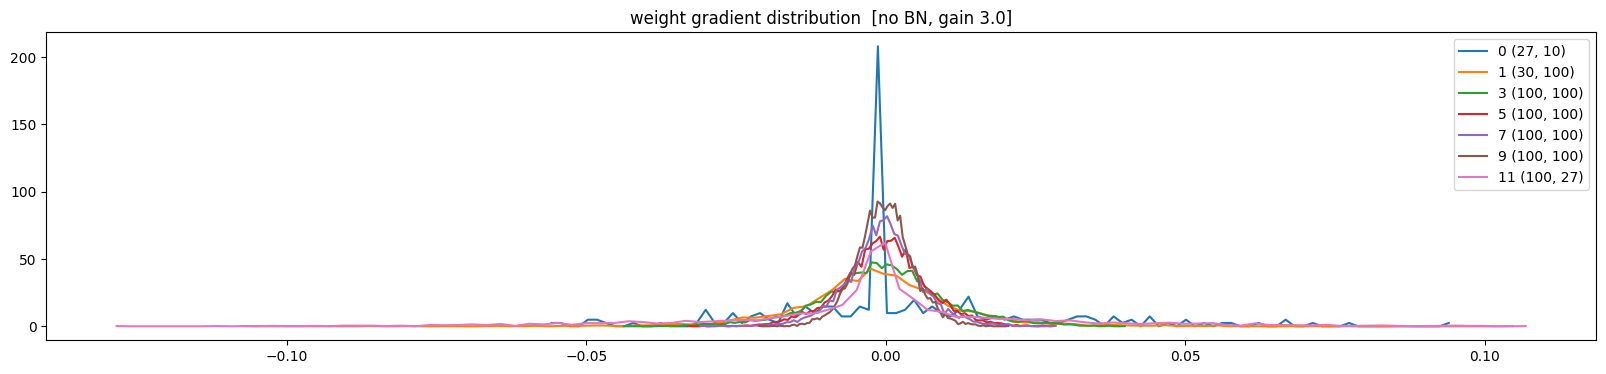

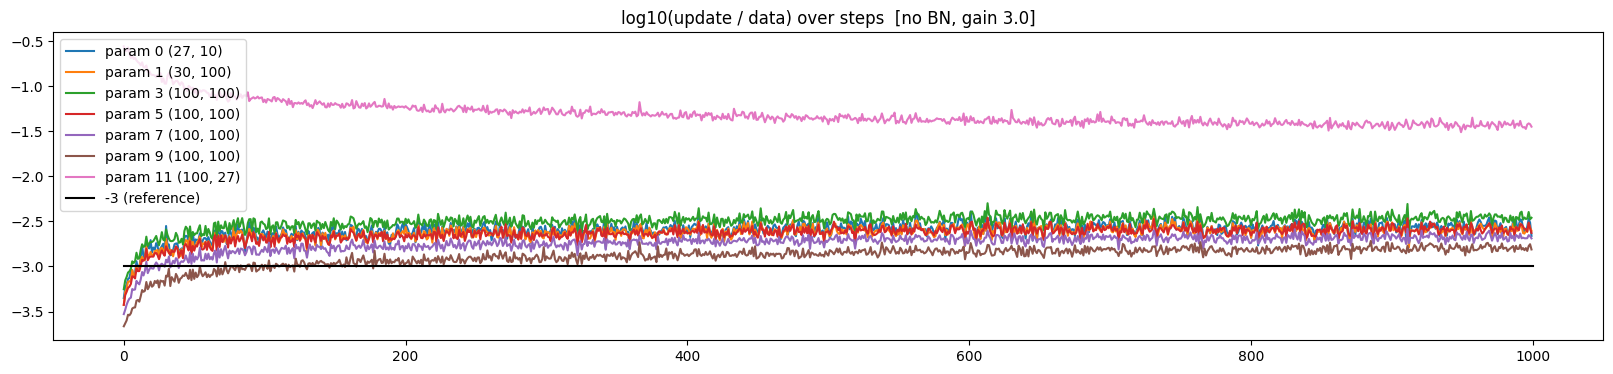

In [52]:
diagnose("no BN, gain 3.0", gain=3.0)

### 实验 4：加上 BatchNorm

每个 tanh 前面都有 BatchNorm，激活值的分布应该在各层都很稳定。

参数总数 47024
[with BN, gain 5/3] 最后 100 步的平均损失 2.4521
layer  2 (Tanh): init std 0.63, saturated  2.81%  |  after training: mean -0.01, std 0.64, saturated  2.16%
layer  5 (Tanh): init std 0.64, saturated  2.53%  |  after training: mean -0.00, std 0.65, saturated  2.34%
layer  8 (Tanh): init std 0.63, saturated  2.78%  |  after training: mean -0.00, std 0.64, saturated  2.59%
layer 11 (Tanh): init std 0.64, saturated  2.78%  |  after training: mean -0.00, std 0.64, saturated  2.16%
layer 14 (Tanh): init std 0.64, saturated  2.34%  |  after training: mean -0.01, std 0.65, saturated  2.13%


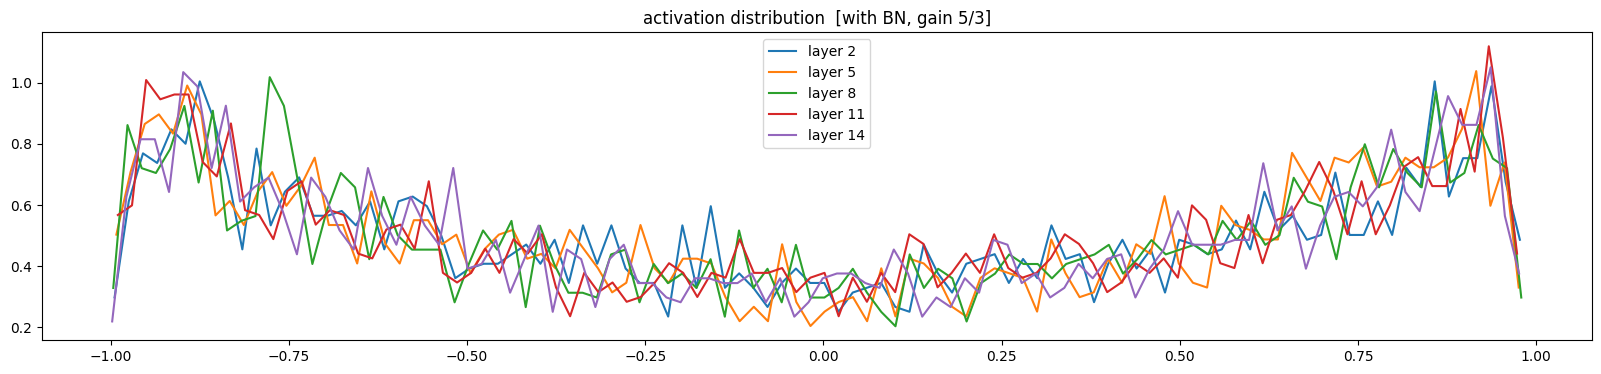

layer  2 (Tanh): grad mean -4.07e-12, grad std 3.00e-03
layer  5 (Tanh): grad mean +8.44e-12, grad std 2.66e-03
layer  8 (Tanh): grad mean +8.44e-12, grad std 2.51e-03
layer 11 (Tanh): grad mean -4.66e-12, grad std 2.31e-03
layer 14 (Tanh): grad mean +3.49e-12, grad std 2.07e-03


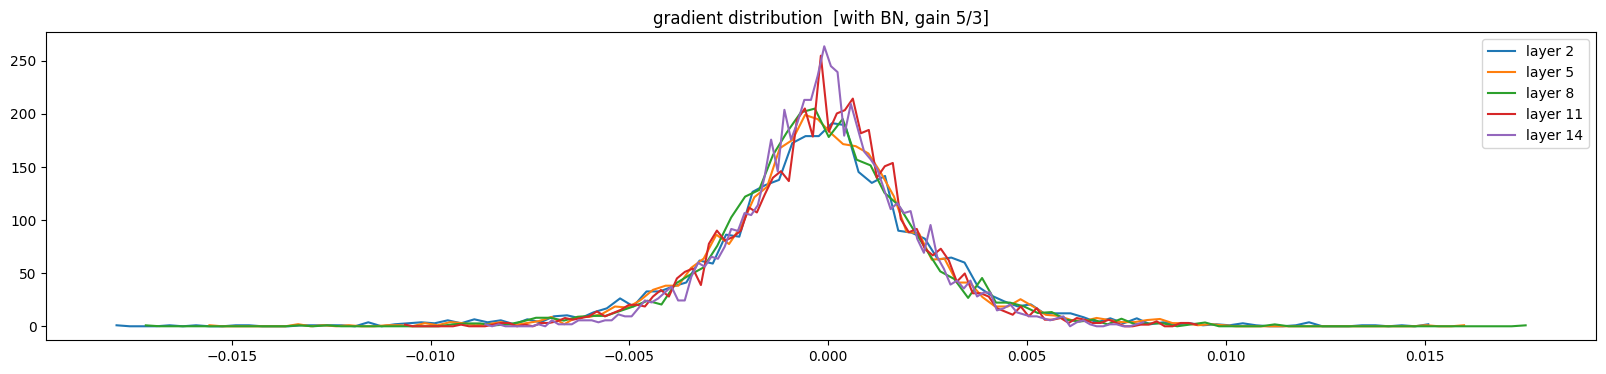

weight (27, 10)   | grad std 7.82e-03 | grad:data ratio 7.81e-03
weight (30, 100)  | grad std 6.80e-03 | grad:data ratio 2.18e-02
weight (100, 100) | grad std 5.68e-03 | grad:data ratio 3.40e-02
weight (100, 100) | grad std 5.11e-03 | grad:data ratio 3.03e-02
weight (100, 100) | grad std 5.02e-03 | grad:data ratio 2.99e-02
weight (100, 100) | grad std 4.50e-03 | grad:data ratio 2.68e-02
weight (100, 27)  | grad std 1.27e-02 | grad:data ratio 1.21e-01


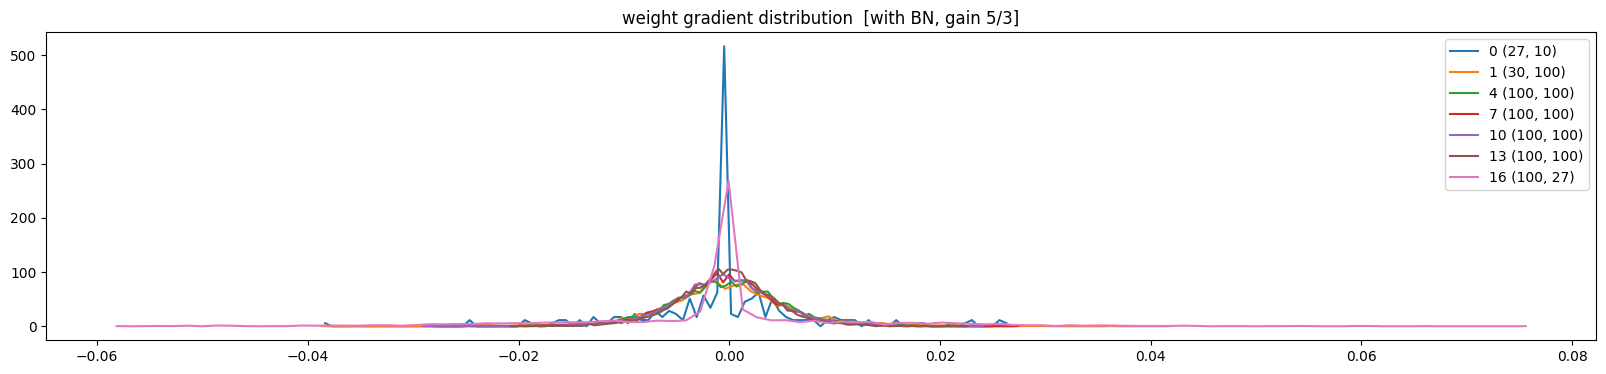

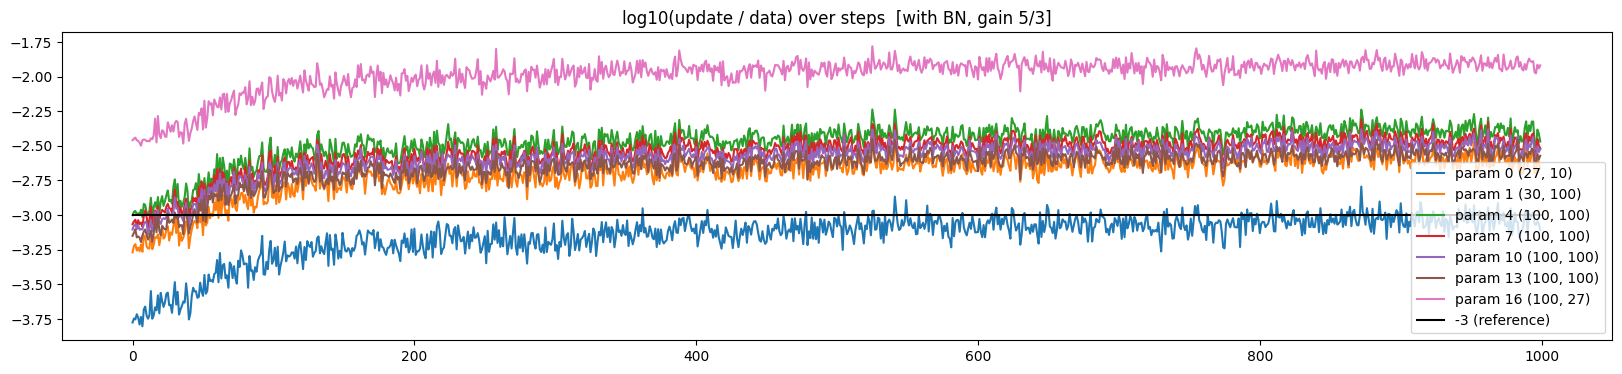

In [53]:
diagnose("with BN, gain 5/3", gain=5 / 3, use_bn=True)

### 实验 5：加上 BatchNorm，但增益故意设得很离谱

BatchNorm 让网络对初始化不再敏感：前向的激活值分布仍然稳定。但要注意第四张图：权重的尺度变了，更新量与参数之比也会跟着变，这时可能需要相应调整学习率。

参数总数 47024
[with BN, gain 0.2] 最后 100 步的平均损失 2.4573
layer  2 (Tanh): init std 0.63, saturated  2.81%  |  after training: mean -0.01, std 0.64, saturated  2.41%
layer  5 (Tanh): init std 0.64, saturated  2.53%  |  after training: mean -0.00, std 0.66, saturated  1.72%
layer  8 (Tanh): init std 0.63, saturated  2.78%  |  after training: mean +0.00, std 0.66, saturated  1.00%
layer 11 (Tanh): init std 0.64, saturated  2.69%  |  after training: mean -0.00, std 0.66, saturated  0.81%
layer 14 (Tanh): init std 0.64, saturated  2.31%  |  after training: mean +0.00, std 0.67, saturated  0.25%


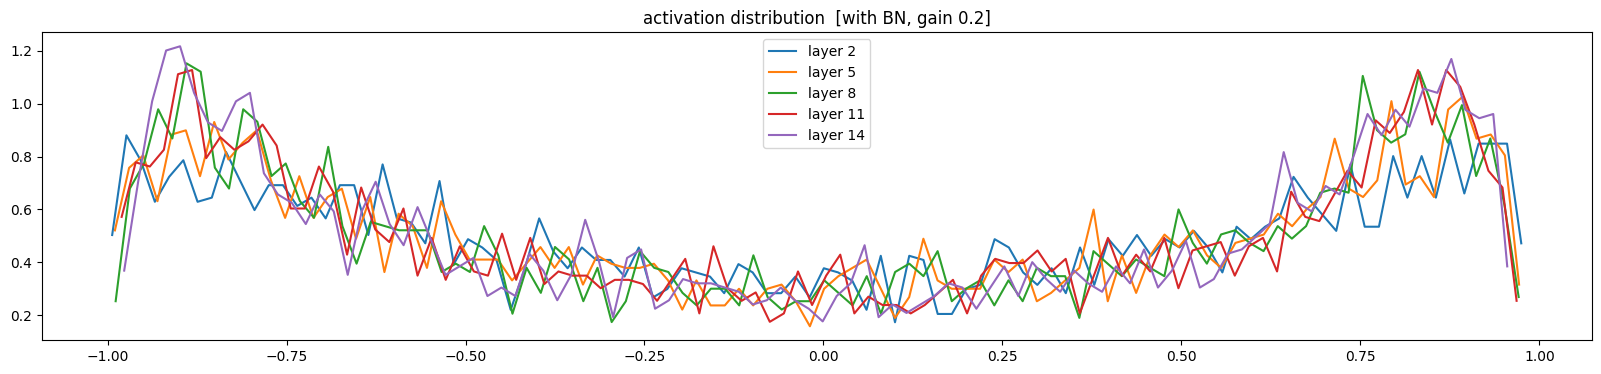

layer  2 (Tanh): grad mean -8.73e-13, grad std 1.38e-03
layer  5 (Tanh): grad mean -1.02e-12, grad std 1.15e-03
layer  8 (Tanh): grad mean +2.62e-12, grad std 9.85e-04
layer 11 (Tanh): grad mean +4.22e-12, grad std 9.57e-04
layer 14 (Tanh): grad mean +1.46e-12, grad std 1.50e-03


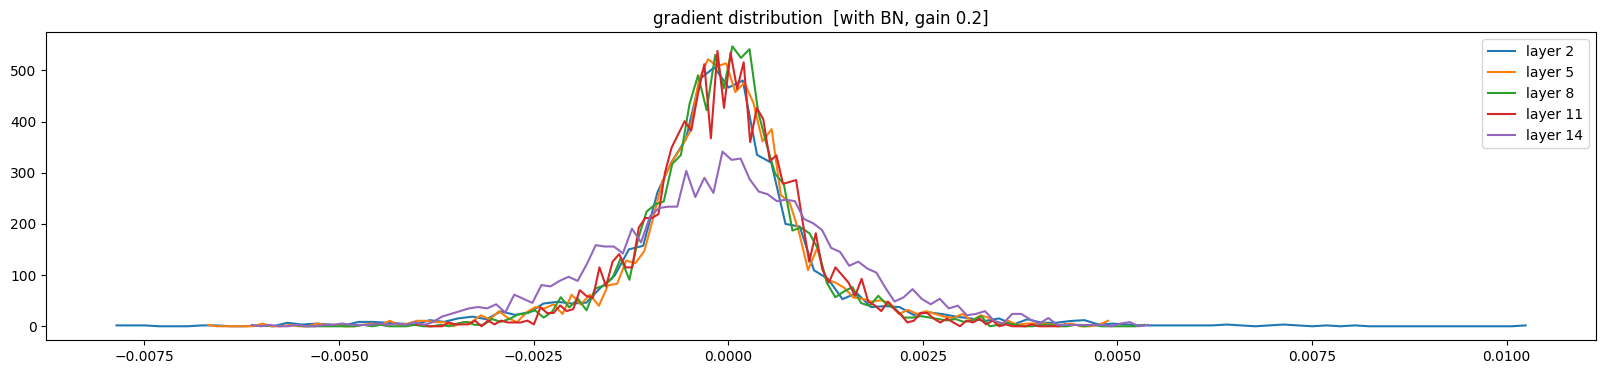

weight (27, 10)   | grad std 7.28e-03 | grad:data ratio 7.27e-03
weight (30, 100)  | grad std 1.43e-02 | grad:data ratio 2.31e-01
weight (100, 100) | grad std 6.13e-03 | grad:data ratio 2.02e-01
weight (100, 100) | grad std 4.92e-03 | grad:data ratio 1.77e-01
weight (100, 100) | grad std 4.52e-03 | grad:data ratio 1.67e-01
weight (100, 100) | grad std 5.57e-03 | grad:data ratio 1.91e-01
weight (100, 27)  | grad std 8.81e-03 | grad:data ratio 8.62e-02


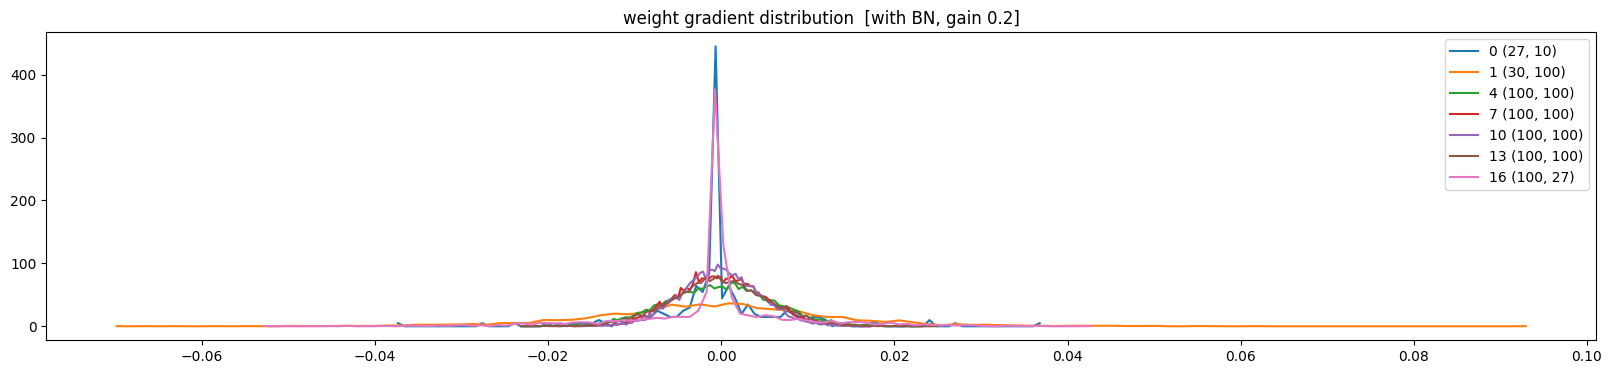

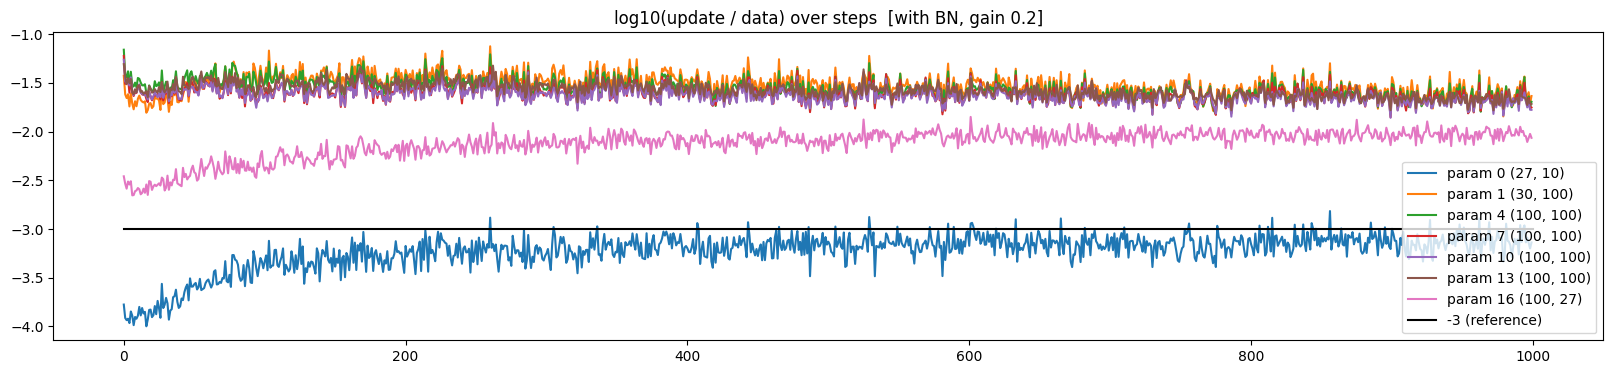

In [54]:
diagnose("with BN, gain 0.2", gain=0.2, use_bn=True)

## 第五部分：完整训练、推理模式与采样

用带 BatchNorm 的深层网络完整训练一遍。训练完后**必须切换到推理模式**：一来要用滑动平均的统计量，二来采样时一次只输入一个样本，在训练模式下算不出有意义的方差。

参数总数 47024
深层网络 + BatchNorm  训练集 2.1391    验证集 2.1542


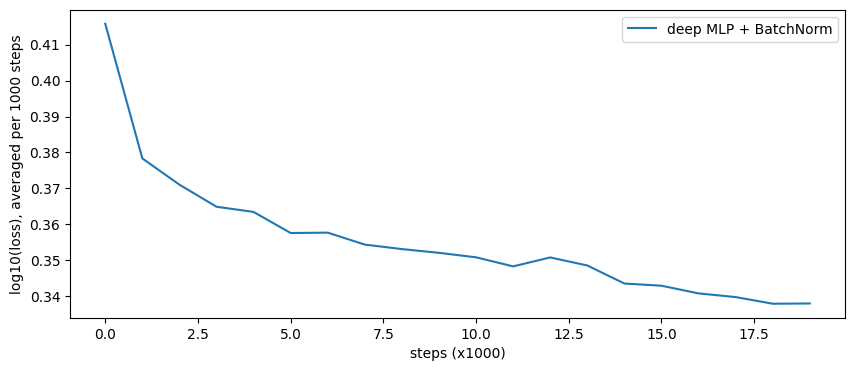

In [55]:
STEPS_FULL = 20000   # 视频用 200000 步；必须是 1000 的整数倍

C_f, layers_f, params_f = build_deep(gain=5 / 3, use_bn=True)
set_training(layers_f, True)
f_deep = lambda X: forward_deep(C_f, layers_f, X)
lossi_f = train_loop(params_f, f_deep, STEPS_FULL,
                     lr_fn=lambda i: 0.1 if i < int(0.75 * STEPS_FULL) else 0.01)

set_training(layers_f, False)   # 切换到推理模式
print(f"深层网络 + BatchNorm  训练集 {split_loss(f_deep, Xtr, Ytr):.4f}    验证集 {split_loss(f_deep, Xva, Yva):.4f}")

plt.figure(figsize=(10, 4))
plt.plot(smooth(lossi_f), label="deep MLP + BatchNorm")
plt.xlabel("steps (x1000)")
plt.ylabel("log10(loss), averaged per 1000 steps")
plt.legend()
plt.show()

In [56]:
g_sample = torch.Generator().manual_seed(2147483647 + 10)

with torch.no_grad():
    for _ in range(20):
        out, context = [], [0] * BLOCK
        while True:
            logits = forward_deep(C_f, layers_f, torch.tensor([context]))   # 一次只输入一个样本
            probs = F.softmax(logits, dim=1)
            ix = torch.multinomial(probs, num_samples=1, generator=g_sample).item()
            context = context[1:] + [ix]
            out.append(ix)
            if ix == 0:          # 采样到 "."，名字结束
                break
        print("".join(itos[i] for i in out))

carlah.
amille.
khi.
mrix.
taty.
skanden.
jazhutn.
dellah.
jareei.
nellara.
chaiivin.
legg.
dham.
joce.
quinn.
sulin.
alianni.
wanthoniearyxi.
jaxeklinsley.
dae.
